# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Sulaiman Faiz Tsaqib | 5054251048 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pd.read_csv('Live.csv')
print(df.shape)
df.info()
display(df.describe())
print(df.isna().sum())
print('Duplikat:', df.drop(columns='status_id').duplicated().sum())

(7050, 16)
<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   str    
 2   status_published  7050 non-null   str    
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(10), str(2)
memory us

,status_id,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
count,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,0.0,0.0,0.0,0.0
mean,3525.500000,230.117163,224.356028,40.022553,215.043121,12.728652,1.289362,0.696454,0.243688,0.113191,NaN,NaN,NaN,NaN
std,2035.304031,462.625309,889.636820,131.599965,449.472357,39.972930,8.719650,3.957183,1.597156,0.726812,NaN,NaN,NaN,NaN
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,1763.250000,17.000000,0.000000,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
50%,3525.500000,59.500000,4.000000,0.000000,58.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
75%,5287.750000,219.000000,23.000000,4.000000,184.750000,3.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
max,7050.000000,4710.000000,20990.000000,3424.000000,4710.000000,657.000000,278.000000,157.000000,51.000000,31.000000,NaN,NaN,NaN,NaN


status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64
Duplikat: 54


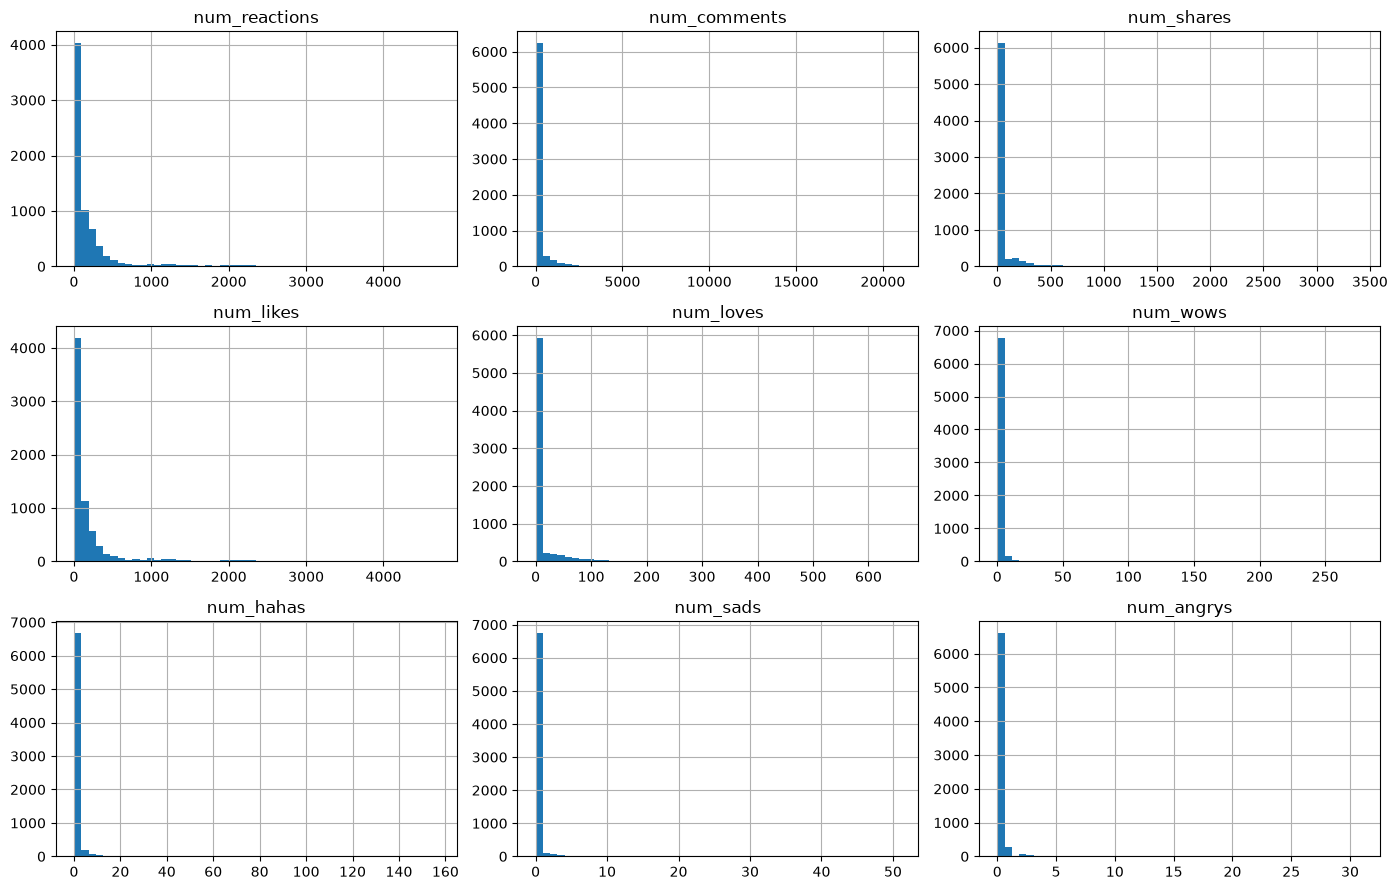

                    skew  proporsi_nol
num_reactions   3.738452      0.017163
num_comments    9.028850      0.300567
num_shares      7.099332      0.554752
num_likes       3.919128      0.017872
num_loves       6.004845      0.600000
num_wows       18.246813      0.752908
num_hahas      20.305741      0.839149
num_sads       17.578868      0.913901
num_angrys     19.507129      0.940000


In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
count_cols = ['num_reactions', 'num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
df[count_cols].hist(bins=50, figsize=(14, 9))
plt.tight_layout()
plt.show()
print(pd.DataFrame({'skew': df[count_cols].skew(), 'proporsi_nol': (df[count_cols] == 0).mean()}))

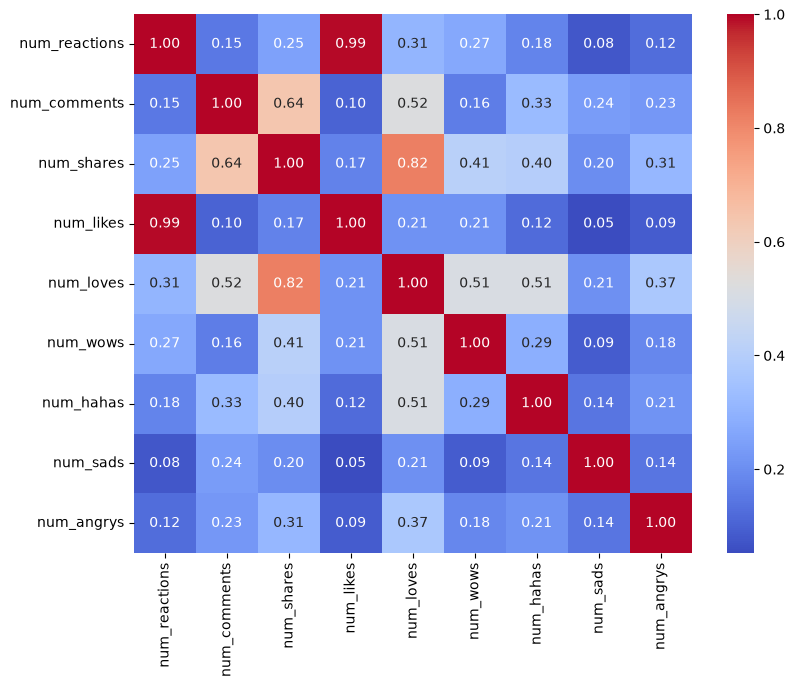

In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
plt.figure(figsize=(9, 7))
sns.heatmap(df[count_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
df['status_published'] = pd.to_datetime(df['status_published'])
emoji = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
df['has_emoji'] = df[emoji].sum(axis=1) > 0
df.groupby(df['status_published'].dt.year).agg(jumlah_post=('status_id', 'count'), proporsi_emoji=('has_emoji', 'mean'))

,jumlah_post,proporsi_emoji
status_published,,
2012,589,0.000000
2013,500,0.000000
2014,233,0.000000
2015,337,0.000000
2016,588,0.680272
2017,2253,0.541944
2018,2550,0.577647


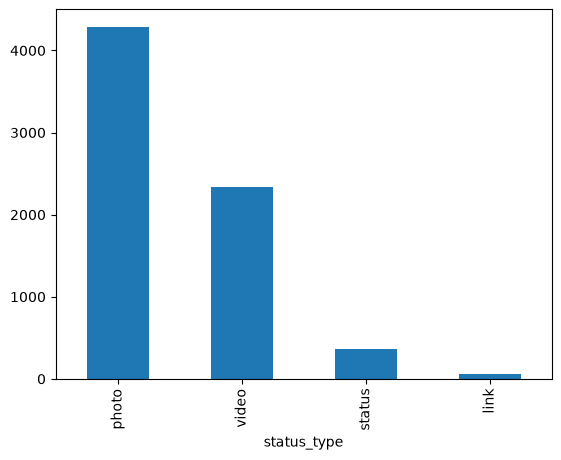

,num_likes,num_comments,num_shares
status_type,,,
link,48.0,1.0,0.0
photo,34.0,2.0,0.0
status,117.0,10.0,0.0
video,117.0,39.0,12.0


In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
df['status_type'].value_counts().plot(kind='bar')
plt.show()
df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [7]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.
df = df.dropna(axis=1, how='all')
df = df.drop_duplicates(subset=df.columns.drop('status_id')).reset_index(drop=True)
print(df.shape, df.isna().sum().sum())
# Outlier ekstrem tidak dihapus karena merupakan posting viral yang nyata; efeknya diredam dengan log1p

(6996, 13) 0


In [8]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.
meta = df[['status_type', 'status_published']]
df['num_emoji_other'] = df[['num_wows', 'num_hahas', 'num_sads', 'num_angrys']].sum(axis=1)
features = ['num_likes', 'num_comments', 'num_shares', 'num_loves', 'num_emoji_other']
X = df[features]
print((df['num_reactions'] == df[['num_likes'] + emoji].sum(axis=1)).mean())
X.describe()

0.9987135506003431


,num_likes,num_comments,num_shares,num_loves,num_emoji_other
count,6996.000000,6996.000000,6996.000000,6996.000000,6996.000000
mean,210.036735,225.648799,40.275872,12.757004,2.294597
std,439.623067,892.922206,132.072584,40.114602,11.073101
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,17.000000,0.000000,0.000000,0.000000,0.000000
50%,57.000000,4.000000,0.000000,0.000000,0.000000
75%,182.000000,22.250000,4.000000,3.000000,1.000000
max,4710.000000,20990.000000,3424.000000,657.000000,286.000000


**Fitur yang dipilih untuk clustering:** `num_likes`, `num_comments`, `num_shares`, `num_loves`, `num_emoji_other`.
- `num_reactions` dibuang karena redundan: nilainya ≈ jumlah likes + seluruh emoji (cocok pada 99.9% baris) dan berkorelasi sangat tinggi dengan `num_likes`.
- `num_wows`, `num_hahas`, `num_sads`, `num_angrys` sangat sparse (75–94% bernilai nol), sehingga digabung menjadi satu fitur `num_emoji_other`.
- `num_loves` dipertahankan terpisah karena paling sering muncul di antara emoji dan cukup informatif.
- `status_id` (ID unik), `status_type` dan `status_published` tidak dipakai sebagai fitur (hanya untuk interpretasi).

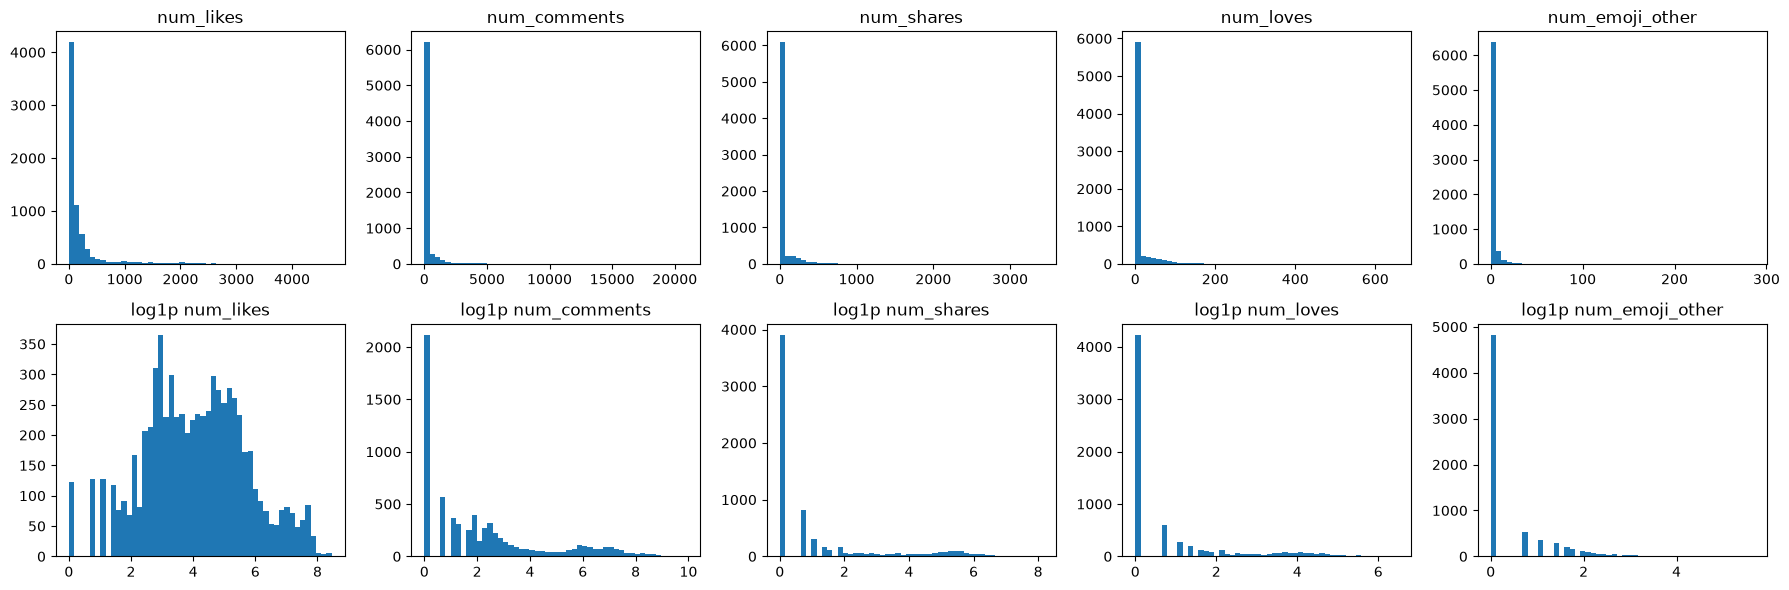

In [9]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.
X_log = np.log1p(X)
fig, ax = plt.subplots(2, len(features), figsize=(18, 6))
for i, f in enumerate(features):
    ax[0, i].hist(X[f], bins=50); ax[0, i].set_title(f)
    ax[1, i].hist(X_log[f], bins=50); ax[1, i].set_title('log1p ' + f)
plt.tight_layout()
plt.show()

In [10]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja
X_log_scaled = StandardScaler().fit_transform(X_log)
X_raw = X.values
X_raw_scaled = StandardScaler().fit_transform(X)

# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [11]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
data = {'raw': X_raw, 'raw_scaled': X_raw_scaled, 'log_scaled': X_log_scaled}
labels_31 = {n: KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(d) for n, d in data.items()}

In [12]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.
pd.DataFrame({n: {'ukuran_cluster': np.bincount(l).tolist(), 'silhouette': silhouette_score(X_log_scaled, l)} for n, l in labels_31.items()}).T

,ukuran_cluster,silhouette
raw,"[6392, 137, 467]",0.298186
raw_scaled,"[292, 6331, 373]",0.241593
log_scaled,"[2200, 3647, 1149]",0.432512


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [13]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.
K = range(2, 11)
inertia = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_log_scaled).inertia_ for k in K]

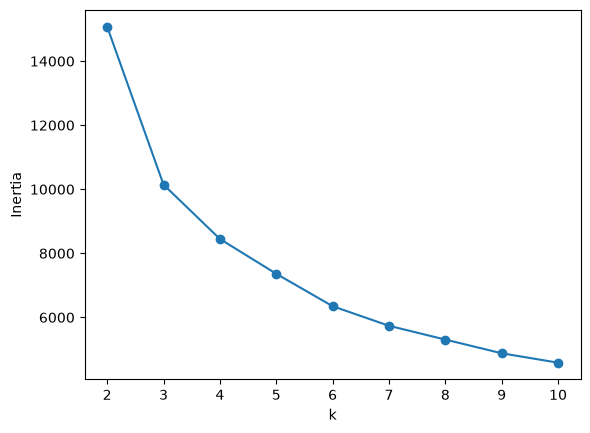

In [14]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.
plt.plot(K, inertia, 'o-')
plt.xlabel('k'); plt.ylabel('Inertia')
plt.show()

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [15]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
sil = [silhouette_score(X_log_scaled, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_log_scaled)) for k in K]
dict(zip(K, np.round(sil, 4)))

{2: np.float64(0.5871),
 3: np.float64(0.4325),
 4: np.float64(0.4122),
 5: np.float64(0.3989),
 6: np.float64(0.3049),
 7: np.float64(0.3104),
 8: np.float64(0.2989),
 9: np.float64(0.3022),
 10: np.float64(0.2984)}

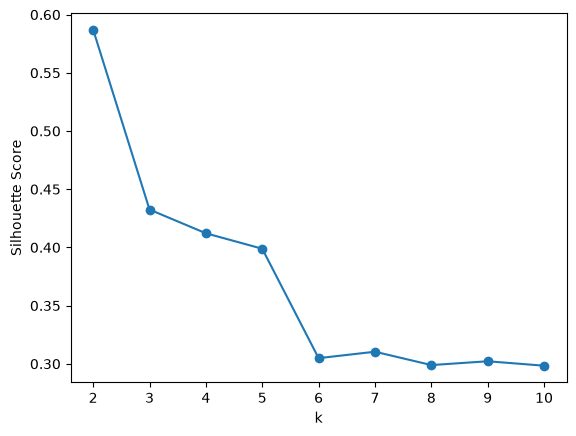

In [16]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.
plt.plot(K, sil, 'o-')
plt.xlabel('k'); plt.ylabel('Silhouette Score')
plt.show()

**Pilihan k untuk K-Means:** k = 3. Elbow terlihat jelas di k = 3 (penurunan inertia 15076 → 10144, lalu hanya → 8449). Silhouette tertinggi memang di k = 2 (0.587), tetapi k = 2 hanya memisahkan posting ramai vs sepi. k = 3 masih memiliki Silhouette yang baik (0.433), sesuai dengan elbow, dan memberi cluster yang lebih bermakna (cluster video live dipisahkan).

## 3.4 Model K-Means Final

In [17]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
k = 3
km_labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_log_scaled)

In [18]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.
X.groupby(km_labels).agg(['median', 'mean']).assign(jumlah=np.bincount(km_labels))

num_likes             num_comments              num_shares              \
     median        mean       median         mean     median        mean   
0     204.5  458.457273         11.0    28.015455        1.0    5.029091   
1      18.0   23.003016          0.0     2.216891        0.0    0.545380   
2     177.0  328.040905        703.0  1313.246301      174.0  233.870322   

  num_loves            num_emoji_other            jumlah  
     median       mean          median       mean         
0       1.0   2.624545             0.0   1.574545   2200  
1       0.0   0.144502             0.0   0.064162   3647  
2      51.0  72.190601             4.0  10.752829   1149

# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [19]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.
Z = linkage(X_log_scaled, method='ward')

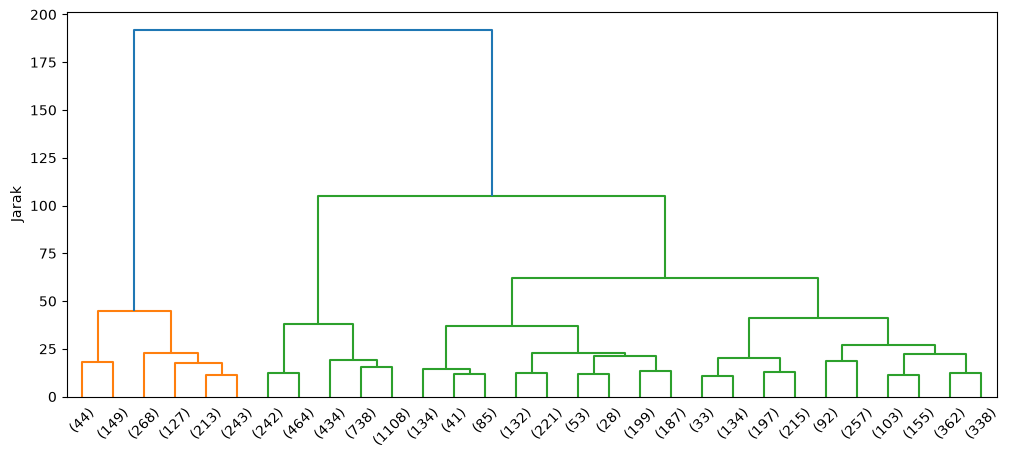

In [20]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=30)
plt.ylabel('Jarak')
plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [21]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.
linkages = ['ward', 'complete', 'average', 'single']
hc_labels = {m: AgglomerativeClustering(n_clusters=k, linkage=m).fit_predict(X_log_scaled) for m in linkages}

In [22]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).
pd.DataFrame({m: {'silhouette': silhouette_score(X_log_scaled, l), 'ukuran_cluster': np.bincount(l).tolist()} for m, l in hc_labels.items()}).T

,silhouette,ukuran_cluster
ward,0.375742,"[2966, 1044, 2986]"
complete,0.478361,"[1246, 347, 5403]"
average,0.572553,"[5892, 1075, 29]"
single,0.352594,"[6994, 1, 1]"


**Pilihan linkage untuk Hierarchical Clustering:** ward. Average (0.573) dan complete (0.478) memiliki Silhouette lebih tinggi, tetapi clusternya tidak seimbang (average punya cluster berisi hanya 29 titik), sedangkan single hampir semua titik masuk satu cluster ([6994, 1, 1]). Ward menghasilkan cluster yang seimbang ([2966, 1044, 2986]) dengan Silhouette yang masih wajar (0.376), sehingga lebih berguna untuk interpretasi.

## 4.3 Model Hierarchical Clustering Final

In [23]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
hc_final = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_log_scaled)

In [24]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
X.groupby(hc_final).agg(['median', 'mean']).assign(jumlah=np.bincount(hc_final))

num_likes             num_comments              num_shares              \
     median        mean       median         mean     median        mean   
0     147.0  380.433243          9.0    27.944370        1.0    5.162171   
1     166.5  277.420498        809.5  1427.880268      192.5  254.451149   
2      14.0   17.222036          0.0     1.690891        0.0    0.271936   

  num_loves            num_emoji_other            jumlah  
     median       mean          median       mean         
0       1.0   2.697910             0.0   1.757923   2966  
1      55.0  77.578544             4.0  10.377395   1044  
2       0.0   0.085064             0.0   0.001674   2986

# 5. Evaluasi Model

In [25]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.
pd.DataFrame({n: {'Silhouette': silhouette_score(X_log_scaled, l), 'Davies-Bouldin': davies_bouldin_score(X_log_scaled, l), 'Calinski-Harabasz': calinski_harabasz_score(X_log_scaled, l)}
              for n, l in {'K-Means': km_labels, 'Hierarchical': hc_final}.items()}).T

,Silhouette,Davies-Bouldin,Calinski-Harabasz
K-Means,0.432512,0.954071,8560.492844
Hierarchical,0.375742,0.947554,7591.122014


Varians dijelaskan: [0.7314104 0.1332936] 0.8647040012481582


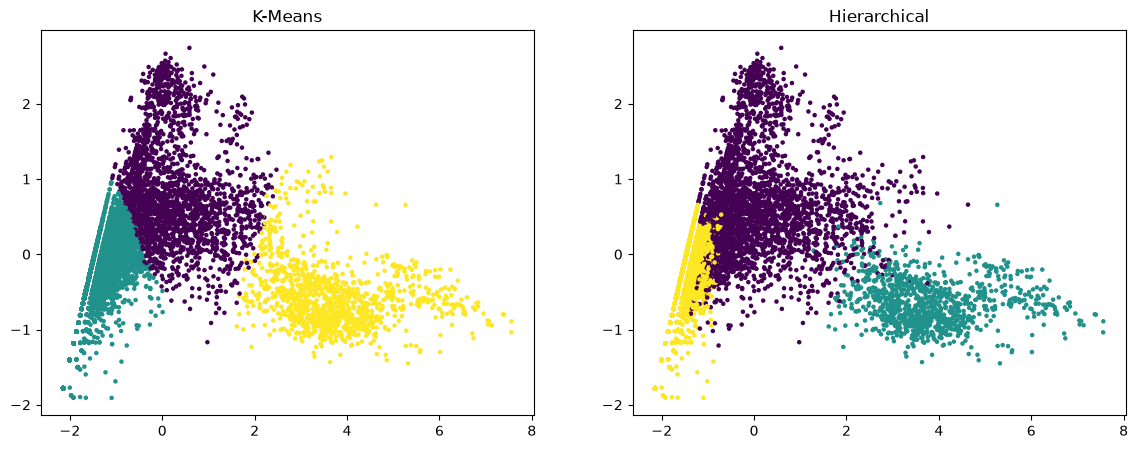

In [26]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_log_scaled)
print('Varians dijelaskan:', pca.explained_variance_ratio_, pca.explained_variance_ratio_.sum())
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (n, l) in zip(ax, {'K-Means': km_labels, 'Hierarchical': hc_final}.items()):
    a.scatter(X_pca[:, 0], X_pca[:, 1], c=l, cmap='viridis', s=5); a.set_title(n)
plt.show()

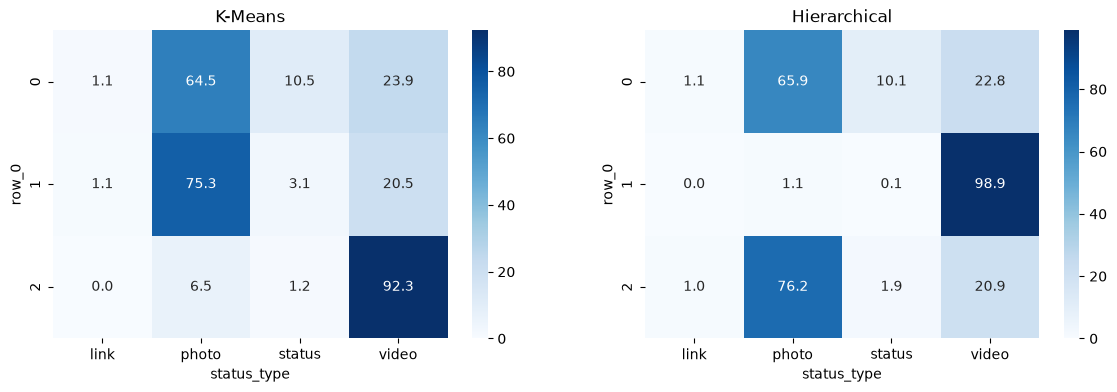

In [27]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, (n, l) in zip(ax, {'K-Means': km_labels, 'Hierarchical': hc_final}.items()):
    sns.heatmap(pd.crosstab(l, meta['status_type'], normalize='index') * 100, annot=True, fmt='.1f', cmap='Blues', ax=a); a.set_title(n)
plt.show()

# 6. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Jelaskan pengaruh transformasi log dan feature scaling pada K-Means berdasarkan hasil pada bagian 3.1. Mengapa keduanya penting pada algoritma berbasis jarak, terutama untuk data yang sangat miring dan mengandung outlier ekstrem?
- Bagaimana kalian menangani kolom yang redundan atau banyak bernilai nol (misalnya reaksi emoji)? Jelaskan alasan pemilihan fitur kalian.
- Berapa jumlah cluster optimal menurut Elbow Method dan Silhouette Score? Apakah keduanya menghasilkan kesimpulan yang sama? Jika berbeda, mana yang kalian pilih dan mengapa?
- Bandingkan hasil keempat metode linkage pada Hierarchical Clustering. Linkage mana yang paling baik dan mengapa? Bagaimana karakteristik cluster yang dihasilkan oleh single linkage?
- Bandingkan performa K-Means vs Hierarchical Clustering berdasarkan metrik internal dan visualisasi PCA. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Bagaimana karakteristik tiap cluster berdasarkan profil median fitur dan komposisi status_type? Beri nama atau julukan yang menggambarkan tiap cluster.
- Apa kelebihan dan kekurangan masing-masing metode (misalnya dari sisi kebutuhan menentukan k di awal, bentuk cluster, dan kebutuhan waktu serta memori)?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

**Jawaban:**

1. **Transformasi log dan scaling (3.1).** Dengan k = 3, data mentah menghasilkan cluster [6392, 137, 467] dan mentah+scaling [292, 6331, 373]: hampir semua data masuk satu cluster, sisanya hanya outlier. Pada data mentah, `num_comments` (std ±893, max 20990) mendominasi jarak Euclidean. Scaling menyamakan skala, tetapi outlier ekstrem tetap menarik centroid. Log1p + scaling meredam skewness dan outlier sehingga cluster lebih seimbang [2200, 3647, 1149] dengan Silhouette tertinggi (0.433 vs 0.298 dan 0.242). Algoritma berbasis jarak sangat sensitif terhadap skala dan nilai ekstrem, sehingga kedua langkah ini penting.
2. **Fitur redundan/sparse.** `num_reactions` dibuang karena merupakan penjumlahan likes + emoji (redundan dan berkorelasi tinggi dengan `num_likes`). Wow, haha, sad, angry (75–94% bernilai nol) digabung menjadi `num_emoji_other` agar tidak menambah dimensi yang hampir selalu nol. `num_loves` dipertahankan. Kolom kosong (Column1–4) dan 54 baris duplikat dihapus. Outlier tidak dihapus karena merupakan posting viral yang nyata.
3. **Jumlah cluster.** Elbow menunjukkan k = 3, sedangkan Silhouette tertinggi di k = 2 (0.587). Keduanya berbeda; k = 3 dipilih karena sesuai elbow, Silhouette masih tinggi (0.433), dan cluster lebih informatif.
4. **Linkage.** Average memiliki Silhouette tertinggi (0.573) tetapi ada cluster berisi 29 titik. Complete juga tidak seimbang ([1246, 347, 5403]). Single paling buruk ([6994, 1, 1]) karena efek *chaining*: cluster terus tersambung lewat titik terdekat sehingga hanya outlier yang terpisah. Ward paling baik untuk interpretasi karena meminimalkan varians dalam cluster (mirip K-Means) dan menghasilkan cluster yang seimbang.
5. **K-Means vs Hierarchical.** K-Means sedikit lebih unggul: Silhouette 0.433 vs 0.376 dan Calinski-Harabasz 8560 vs 7591, sedangkan Davies-Bouldin hampir sama (0.954 vs 0.948). Pada PCA (86.5% varians dijelaskan oleh 2 komponen) pola keduanya mirip (ARI ≈ 0.67). Perbedaannya terutama ada di batas antara cluster sepi dan sedang. Hasil tidak berbeda signifikan karena ward dan K-Means sama-sama meminimalkan varians dalam cluster, hanya saja K-Means mengoptimasi secara iteratif, sedangkan ward bersifat greedy dan tidak dapat memperbaiki penggabungan sebelumnya.
6. **Karakteristik cluster (K-Means).**
   - *"Video Viral"* (1149 post): median 703 komentar, 174 share, 51 love; 92% video, seluruhnya ≥2016 (era live/reaksi).
   - *"Foto Populer"* (2200 post): median 204 like, 11 komentar; mayoritas foto (64.5%) ditambah status/video, engagement sedang-tinggi pada like.
   - *"Posting Sepi"* (3647 post): median 18 like, 0 komentar, 0 share; 75% foto.
   Pola pada Hierarchical (ward) hampir sama: cluster video (98.9% video, 1044 post), cluster foto populer, dan cluster sepi.
7. **Kelebihan dan kekurangan.** K-Means cepat dan hemat memori (O(nk)) serta cocok untuk data besar, tetapi k harus ditentukan di awal, mengasumsikan cluster berbentuk bulat, dan sensitif terhadap outlier serta inisialisasi. Hierarchical tidak perlu menentukan k di awal (dapat dibaca dari dendrogram) dan dapat membentuk cluster non-bulat (single/average), tetapi butuh memori O(n²) dan waktu yang lebih lama, penggabungannya tidak dapat dikoreksi, dan hasilnya sangat bergantung pada pilihan linkage.

# 7. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya melakukan clustering terpisah untuk periode sebelum dan sesudah tahun 2016, memanfaatkan fitur waktu seperti jam atau hari posting, mencoba algoritma clustering lain seperti DBSCAN atau Gaussian Mixture Model, melakukan reduksi dimensi sebelum clustering, atau mencoba variasi hyperparameter lain seperti n_init dan init pada K-Means), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

**Kesimpulan:**
- Transformasi log1p dan StandardScaler wajib dilakukan pada data engagement yang sangat miring; tanpa keduanya, clustering hanya memisahkan outlier.
- Jumlah cluster optimal adalah k = 3 (elbow), dengan Silhouette K-Means 0.433.
- K-Means sedikit lebih baik daripada Hierarchical (ward) pada Silhouette dan Calinski-Harabasz, dengan pola cluster yang mirip: *Video Viral*, *Foto Populer*, dan *Posting Sepi*.
- Video (terutama sejak 2016) menghasilkan engagement komentar dan share jauh lebih tinggi dibanding foto.

**Saran:**
- Lakukan clustering terpisah untuk periode sebelum dan sesudah 2016, karena reaksi emoji baru muncul sejak 2016.
- Tambahkan fitur waktu (jam/hari posting).
- Coba DBSCAN atau Gaussian Mixture Model untuk cluster non-bulat dan deteksi outlier.
- Coba variasi `n_init`/`init` pada K-Means dan reduksi dimensi sebelum clustering.